# Análisis Exploratorio de Datos (EDA) - Rendimiento Académico

# 1.Importación librerías

In [1]:
import sys
sys.path.append('..') #para poder importar la carpeta src desde notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_prep import Preprocesador

# 2.Importación fuente de datos

In [2]:
#Usamos la clase Preprocesador para cargar y unir las dos materias (sin repetir código)
prep = Preprocesador()
df = prep.cargar_datos()

#Agregamos las variables derivadas y el nivel de riesgo para poder analizarlos también
prep.crear_variables_derivadas()
prep.crear_nivel_riesgo()
df.shape

(1044, 37)

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,Walc,health,absences,G1,G2,G3,materia,promedio_notas,tasa_ausencias,nivel_riesgo
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,1,3,6,5,6,6,matematicas,5.5,0.064516,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,1,3,4,5,5,6,matematicas,5.0,0.043011,4
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,3,10,7,8,10,matematicas,7.5,0.107527,3
3,GP,F,15,U,GT3,T,4,2,health,services,...,1,5,2,15,14,15,matematicas,14.5,0.021505,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,2,5,4,6,10,10,matematicas,8.0,0.043011,3


# 3.Descripción general de los datos

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 37 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   school          1044 non-null   str    
 1   sex             1044 non-null   str    
 2   age             1044 non-null   int64  
 3   address         1044 non-null   str    
 4   famsize         1044 non-null   str    
 5   Pstatus         1044 non-null   str    
 6   Medu            1044 non-null   int64  
 7   Fedu            1044 non-null   int64  
 8   Mjob            1044 non-null   str    
 9   Fjob            1044 non-null   str    
 10  reason          1044 non-null   str    
 11  guardian        1044 non-null   str    
 12  traveltime      1044 non-null   int64  
 13  studytime       1044 non-null   int64  
 14  failures        1044 non-null   int64  
 15  schoolsup       1044 non-null   str    
 16  famsup          1044 non-null   str    
 17  paid            1044 non-null   str    
 18 

In [5]:
df.describe().transpose() #Principales datos estadísticos del dataframe, la variable objetivo es G3

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.000000,18.000000,22.000000
Medu,1044.0,2.603448,1.124907,0.0,2.0,3.000000,4.000000,4.000000
Fedu,1044.0,2.387931,1.099938,0.0,1.0,2.000000,3.000000,4.000000
traveltime,1044.0,1.522989,0.731727,1.0,1.0,1.000000,2.000000,4.000000
studytime,1044.0,1.970307,0.834353,1.0,1.0,2.000000,2.000000,4.000000
failures,1044.0,0.264368,0.656142,0.0,0.0,0.000000,0.000000,3.000000
famrel,1044.0,3.935824,0.933401,1.0,4.0,4.000000,5.000000,5.000000
freetime,1044.0,3.201149,1.031507,1.0,3.0,3.000000,4.000000,5.000000
goout,1044.0,3.156130,1.152575,1.0,2.0,3.000000,4.000000,5.000000
Dalc,1044.0,1.494253,0.911714,1.0,1.0,1.000000,2.000000,5.000000


In [6]:
#¿Cuántos estudiantes hay por materia y por escuela?
pd.crosstab(df['materia'], df['school'], margins=True)

school,GP,MS,All
materia,,,
matematicas,349,46,395
portugues,423,226,649
All,772,272,1044


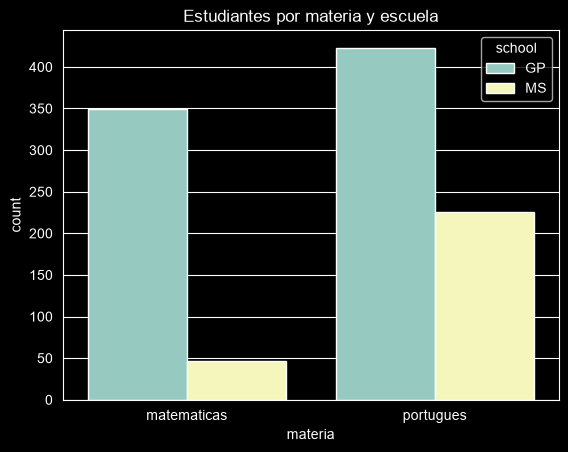

In [7]:
#Gráfico de estudiantes por materia y escuela
sns.countplot(x='materia', hue='school', data=df)
plt.title('Estudiantes por materia y escuela')
plt.show()

**Observaciones generales**

- El dataset tiene 1044 registros: 395 de matemáticas y 649 de portugués.
- La mayoría de los estudiantes son de la escuela Gabriel Pereira (GP: 772) y el resto de Mousinho da Silveira (MS: 272).
- La nota final G3 tiene un promedio de 11.3 sobre 20, con una mediana de 11

# 4.Variable objetivo: nota final (G3)

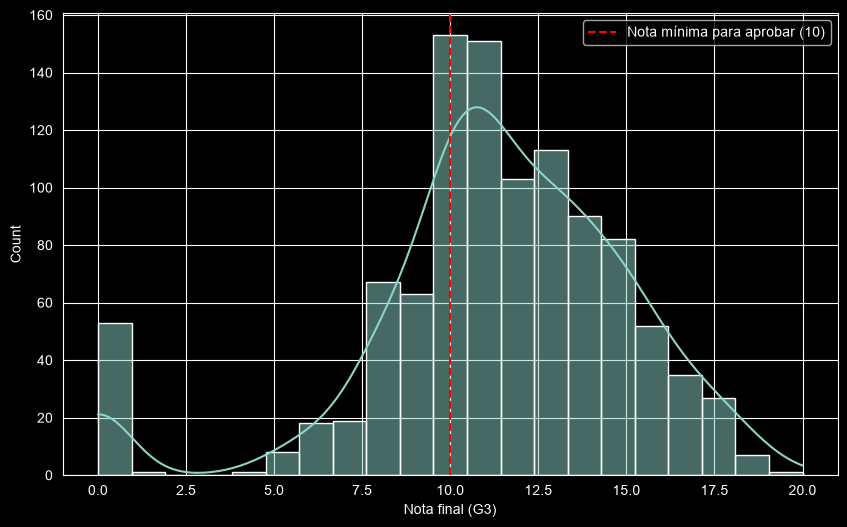

In [8]:
#Distribución de la nota final G3 (escala 0 a 20)
plt.figure(figsize=(10,6))
sns.histplot(df['G3'], bins=21, kde=True)
plt.axvline(10, color='r', linestyle='--', label='Nota mínima para aprobar (10)')
plt.xlabel('Nota final (G3)')
plt.legend()
plt.show()

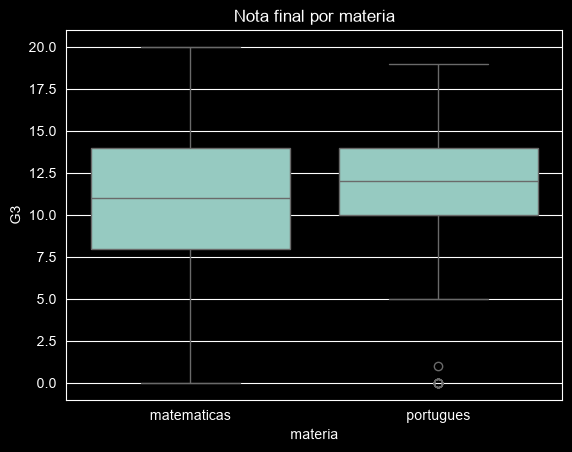

In [9]:
#¿Hay diferencia en la nota final entre matemáticas y portugués?
sns.boxplot(x='materia', y='G3', data=df)
plt.title('Nota final por materia')
plt.show()

In [10]:
df.groupby('materia')['G3'].agg(['mean','median','std'])

,mean,median,std
materia,,,
matematicas,10.415190,11.0,4.581443
portugues,11.906009,12.0,3.230656


In [11]:
#Porcentaje de estudiantes que reprueban (G3 < 10) por materia
(df['G3'] < 10).groupby(df['materia']).mean() * 100

materia
matematicas    32.911392
portugues      15.408320
Name: G3, dtype: float64

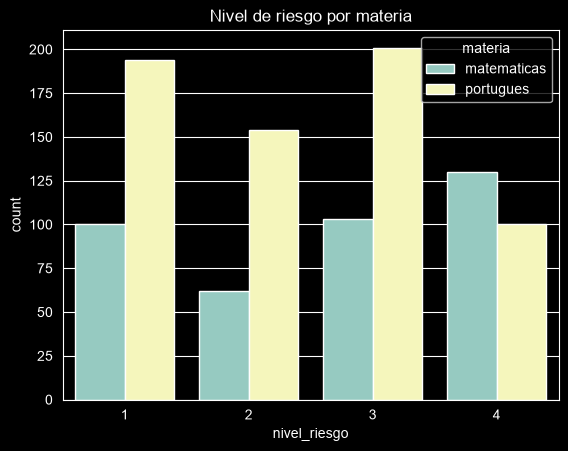

In [12]:
#Distribución del nivel de riesgo (1 = Sin riesgo, 2 = Bajo, 3 = Medio, 4 = Alto)
sns.countplot(x='nivel_riesgo', hue='materia', data=df)
plt.title('Nivel de riesgo por materia')
plt.show()

**Observaciones de la nota final (G3)**

- La nota más frecuente es 10 y la mayoría de los estudiantes está entre 8 y 15.
- Hay un grupo separado de 53 estudiantes con nota 0, que probablemente abandonaron o no se presentaron al examen final.
- El 22 % de los estudiantes reprueba (G3 < 10).
- Matemáticas es más difícil: promedio de 10.4 contra 11.9 en portugués, sus notas están más dispersas, y reprueba el 32.9 % en matemáticas contra el 15.4 % en portugués.
- En el nivel de riesgo alto (4) hay más estudiantes de matemáticas que de portugués, aunque portugués tiene muchos más estudiantes en total.

# 5.Notas parciales (G1 y G2)

In [13]:
#Correlación entre las tres notas
df[['G1','G2','G3']].corr()

,G1,G2,G3
G1,1.000000,0.858739,0.809142
G2,0.858739,1.000000,0.910743
G3,0.809142,0.910743,1.000000


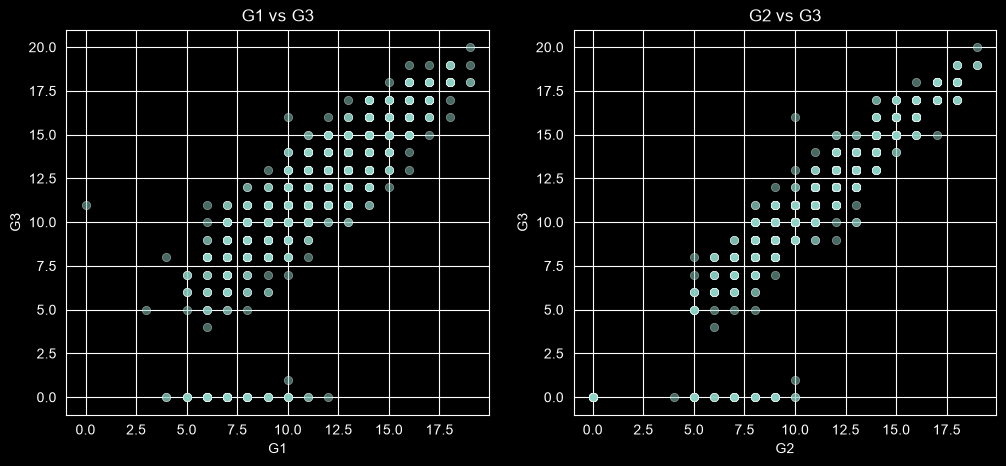

In [14]:
#Visualizar la relación de las notas parciales con la nota final
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.scatterplot(x='G1', y='G3', data=df, ax=axes[0], alpha=0.5)
axes[0].set_title('G1 vs G3')
sns.scatterplot(x='G2', y='G3', data=df, ax=axes[1], alpha=0.5)
axes[1].set_title('G2 vs G3')
plt.show()

In [15]:
#¿Qué porcentaje de estudiantes tiene una nota final igual o muy cercana (±1 punto) a la del segundo periodo?
print('G3 igual a G2:', round((df['G2'] == df['G3']).mean() * 100, 1), '%')
print('G3 a ±1 punto de G2:', round(((df['G3'] - df['G2']).abs() <= 1).mean() * 100, 1), '%')

G3 igual a G2: 46.1 %
G3 a ±1 punto de G2: 88.3 %


**Observaciones de las notas parciales**

- G1 y G2 tienen una correlación muy alta con la nota final (0.81 y 0.91).
- El 46 % de los estudiantes tiene exactamente la misma nota en G2 y en G3, y el 88 % está a un punto o menos.
- En los gráficos se ve una línea casi recta: quien va bien en el periodo, termina bien el año.
- Los puntos en G3 = 0 con G1 o G2 mayores que 0 son los estudiantes que abandonaron: tenían nota durante el año, pero no en el final.
- Por eso el Modelo 1 se compara con y sin G1/G2: con ellas la predicción es muy buena, pero llega tarde para una alerta temprana.

# 6.Factores académicos

# 7.Factores familiares y sociales

# 8.Correlación con la nota final

# 9.Conclusiones del EDA